# 04 · Churn Prediction (Model 1 — Classification)

**Netflix Customer Intelligence, Churn Prediction & AI Analytics Copilot** · Week 2, Days 3–4

**Question:** which customers who are active today will cancel in the next ~6 months, and how should a retention team use that?

| | |
|---|---|
| **Data** | `customer_features_train.csv` from notebook 03: 6,939 customers active on 2025-12-31, described only by data up to that date |
| **Target** | `churn_next_6m` = 1 if the customer cancelled between 2026-01-01 and 2026-06-30 (about 18% of customers) |
| **Models** | Logistic Regression, Random Forest, Gradient Boosting and XGBoost (if installed), against a "no skill" baseline |
| **Handled** | train/test split, categorical encoding, class imbalance (class weights), 5-fold cross-validation, hyper-parameter search, probability calibration |
| **Metrics** | Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, confusion matrix, plus the business view: lift, gain and net benefit of a retention offer |

**Reading note.** This dataset is deliberately noisy, and the honest ROC-AUC is modest (about 0.6–0.65). Section 9 shows why a score of 0.99 would be a mistake: features measured at the end of the data simply reveal who already left.

In [7]:
PREFIX = "churn"

import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder that contains src/utils/config.py)
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src" / "utils" / "config.py").exists()), None)
if ROOT is None:                          # fallback: an environment variable set before starting Jupyter
    import os
    _env = os.environ.get("NETFLIX_PROJECT_ROOT", "")
    if _env and (Path(_env) / "src" / "utils" / "config.py").exists():
        ROOT = Path(_env).resolve()
assert ROOT is not None, (f"This notebook is running in {Path.cwd()}, which is not inside the project folder. "
                          "Open the copy in <project>/notebooks (start Jupyter from the project root), "
                          "or set the NETFLIX_PROJECT_ROOT environment variable.")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

PROCESSED = ROOT / "data" / "processed"
MODELS    = ROOT / "models"
REPORTS   = ROOT / "reports"
FIG_DIR   = REPORTS / "figures"
for d in (PROCESSED, MODELS, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

NETFLIX_RED, DARK, GREY, BLUE = "#E50914", "#221F1F", "#8C8C8C", "#3B6EA8"
sns.set_theme(style="whitegrid", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 13})


def finish(num, name, fig=None):
    """Tidy the figure, save it to reports/figures and show it."""
    fig = fig or plt.gcf()
    fig.tight_layout()
    path = FIG_DIR / f"{PREFIX}_{num:02d}_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved chart: {path.relative_to(ROOT)}")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix)
from scipy.stats import loguniform
import joblib

from src.features import build_features as bf
from src.models.utils import bootstrap_ci, classification_report_row, threshold_table, gain_curve

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception as exc:                      # the notebook still works without XGBoost
    HAS_XGB = False
    print("XGBoost is not available, so it is skipped:", exc)

RANDOM_STATE = 42
N_ITER = 12            # hyper-parameter combinations tried per model (raise it for a wider search)
print("Setup done. Project root:", ROOT)

Setup done. Project root: <project folder>


## 1 · Data and split

In [8]:
data = pd.read_csv(PROCESSED / "customer_features_train.csv", index_col="customer_id",
                   keep_default_na=False, na_values=[""])
meta = json.load(open(PROCESSED / "feature_meta.json"))
TARGET = "churn_next_6m"

X, y = data[bf.FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f"All customers : {len(X):,}   churn rate {y.mean():.1%}")
print(f"Train         : {len(X_train):,}   churn rate {y_train.mean():.1%}")
print(f"Test (hold-out): {len(X_test):,}   churn rate {y_test.mean():.1%}   <- not touched until the final evaluation")

All customers : 6,939   churn rate 18.0%
Train         : 5,204   churn rate 18.0%
Test (hold-out): 1,735   churn rate 18.0%   <- not touched until the final evaluation


## 2 · Pipelines

Every model is a single scikit-learn `Pipeline`, so imputation, scaling and encoding are learned **inside** each cross-validation fold (no leakage from the validation fold).

- **Numeric features:** median imputation + a "was missing" flag (a missing satisfaction score means "no resolved ticket", which is informative); standardised for Logistic Regression only.
- **Categorical features:** one-hot encoding; rare categories (< 1%) are grouped together; unseen categories at scoring time are ignored.
- **Class imbalance (18% churners):** class weights (`balanced`) for Logistic Regression, Random Forest and Gradient Boosting, and `scale_pos_weight` for XGBoost. Probabilities are calibrated afterwards so they can be read as real risks.

In [9]:
def preprocessor(scale: bool) -> ColumnTransformer:
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), bf.NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False))]),
         bf.CATEGORICAL),
    ])


def make_models() -> dict:
    neg_pos = (y_train == 0).sum() / (y_train == 1).sum()
    models = {
        "Logistic Regression": Pipeline([("prep", preprocessor(True)),
            ("model", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000))]),
        "Random Forest": Pipeline([("prep", preprocessor(False)),
            ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                                             class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("prep", preprocessor(False)),
            ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=150, l2_regularization=1.0,
                                                     class_weight="balanced", random_state=RANDOM_STATE))]),
    }
    if HAS_XGB:
        models["XGBoost"] = Pipeline([("prep", preprocessor(False)),
            ("model", XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                                    reg_lambda=5.0, scale_pos_weight=neg_pos, eval_metric="logloss",
                                    random_state=RANDOM_STATE, n_jobs=-1))])
    return models

models = make_models()
print("Models:", ", ".join(models), "| baseline: always predicts the base rate")

Models: Logistic Regression, Random Forest, Gradient Boosting, XGBoost | baseline: always predicts the base rate


## 3 · Cross-validated comparison (default settings)

Five-fold stratified cross-validation **on the training set only**. ROC-AUC and PR-AUC do not depend on a threshold; precision, recall and F1 here use the default 0.5 cut-off, which is rarely the right one for an imbalanced problem (Section 6 chooses a proper threshold).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "precision": "precision", "recall": "recall"}

candidates = {"Baseline (base rate)": Pipeline([("prep", preprocessor(False)), ("model", DummyClassifier(strategy="prior"))]),
              **models}
rows = []
for name, model in candidates.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring},
                 "roc_auc_std": r["test_roc_auc"].std(), "pr_auc_std": r["test_pr_auc"].std()})
cv_default = pd.DataFrame(rows).set_index("model")
display(cv_default.round(3))

,roc_auc,pr_auc,f1,precision,recall,roc_auc_std,pr_auc_std
model,,,,,,,
Baseline (base rate),0.500,0.180,0.000,0.000,0.000,0.000,0.000
Logistic Regression,0.615,0.259,0.337,0.243,0.551,0.010,0.009
Random Forest,0.610,0.258,0.295,0.273,0.321,0.019,0.018
Gradient Boosting,0.609,0.264,0.329,0.252,0.474,0.011,0.014
XGBoost,0.601,0.255,0.315,0.244,0.445,0.012,0.015


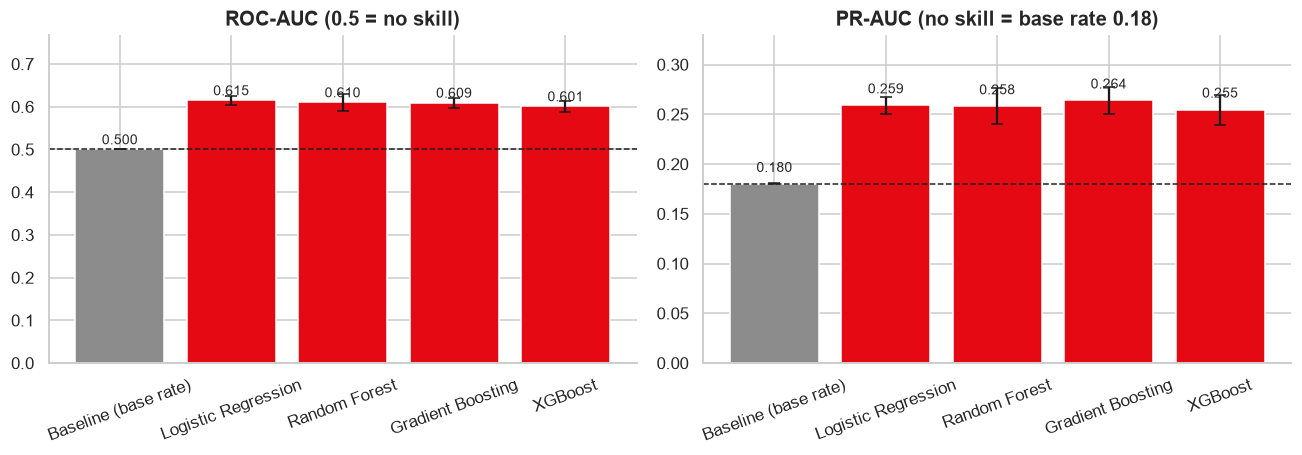

Saved chart: reports\figures\churn_01_model_comparison_cv.png


In [11]:
# Chart 1 — Cross-validated ROC-AUC and PR-AUC for every model (error bars = std over the 5 folds)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
base_rate = y_train.mean()
for ax, metric, ref, title in [(axes[0], "roc_auc", 0.5, "ROC-AUC (0.5 = no skill)"),
                               (axes[1], "pr_auc", base_rate, f"PR-AUC (no skill = base rate {base_rate:.2f})")]:
    d = cv_default[metric]; e = cv_default[f"{metric}_std"]
    colors = [GREY if "Baseline" in n else NETFLIX_RED for n in d.index]
    ax.bar(d.index, d.values, yerr=e.values, color=colors, capsize=4)
    ax.axhline(ref, color=DARK, ls="--", lw=1)
    for x, v in enumerate(d.values): ax.text(x, v + 0.012, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_title(title); ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, max(d.values) * 1.25)
finish(1, "model_comparison_cv", fig)

## 4 · Hyper-parameter search

Randomised search with the same 5 folds, optimising **PR-AUC** (average precision), the metric that matters when the positive class is the minority and the business acts on the top of the ranking. ROC-AUC is tracked alongside.

In [12]:
spaces = {
    "Logistic Regression": {"model__C": loguniform(1e-3, 1e1)},
    "Random Forest": {"model__n_estimators": [200, 300, 500], "model__max_depth": [4, 6, 8, None],
                      "model__min_samples_leaf": [10, 20, 40, 80], "model__max_features": ["sqrt", 0.3, 0.5]},
    "Gradient Boosting": {"model__learning_rate": [0.02, 0.05, 0.1], "model__max_depth": [2, 3, 4],
                          "model__max_iter": [100, 200, 300], "model__l2_regularization": [0.0, 1.0, 10.0],
                          "model__min_samples_leaf": [20, 50, 100]},
    "XGBoost": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.02, 0.05, 0.1],
                "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.9], "model__colsample_bytree": [0.5, 0.8],
                "model__reg_lambda": [1.0, 5.0, 20.0]},
}
tuned, rows = {}, []
for name, model in models.items():
    search = RandomizedSearchCV(model, spaces[name], n_iter=N_ITER, cv=cv, random_state=RANDOM_STATE, n_jobs=1,
                                scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, refit="pr_auc")
    search.fit(X_train, y_train)
    tuned[name] = search
    i = search.best_index_
    rows.append({"model": name, "cv_pr_auc": search.cv_results_["mean_test_pr_auc"][i],
                 "cv_pr_auc_std": search.cv_results_["std_test_pr_auc"][i],
                 "cv_roc_auc": search.cv_results_["mean_test_roc_auc"][i],
                 "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    print(f"{name:20s} CV PR-AUC {rows[-1]['cv_pr_auc']:.3f}   CV ROC-AUC {rows[-1]['cv_roc_auc']:.3f}")
tuned_table = pd.DataFrame(rows).set_index("model")
display(tuned_table)

Logistic Regression  CV PR-AUC 0.270   CV ROC-AUC 0.629
Random Forest        CV PR-AUC 0.267   CV ROC-AUC 0.616
Gradient Boosting    CV PR-AUC 0.273   CV ROC-AUC 0.617
XGBoost              CV PR-AUC 0.279   CV ROC-AUC 0.623


,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,best_params
model,,,,
Logistic Regression,0.269986,0.011876,0.629290,{'C': 0.0017073967431528124}
Random Forest,0.267091,0.012729,0.615829,"{'n_estimators': 200, 'min_samples_leaf': 40, ..."
Gradient Boosting,0.273411,0.010084,0.616844,"{'min_samples_leaf': 20, 'max_iter': 300, 'max..."
XGBoost,0.278661,0.015280,0.622750,"{'subsample': 0.9, 'reg_lambda': 20.0, 'n_esti..."


In [13]:
# Choose the final model: highest cross-validated PR-AUC; if several are within 0.005, prefer the simplest.
complexity = {"Logistic Regression": 0, "Gradient Boosting": 1, "XGBoost": 1, "Random Forest": 2}
best = tuned_table.cv_pr_auc.max()
near_best = tuned_table[tuned_table.cv_pr_auc >= best - 0.005].index.tolist()
final_name = min(near_best, key=lambda n: (complexity[n], -tuned_table.cv_pr_auc[n]))
print("Within 0.005 of the best CV PR-AUC:", near_best)
print("Final model:", final_name)
final_base = tuned[final_name].best_estimator_          # already refit on the whole training set

Within 0.005 of the best CV PR-AUC: ['XGBoost']
Final model: XGBoost


## 5 · Final model: calibrated probabilities

Class weights make a model over-predict churn, so its raw scores are not real probabilities. Wrapping the chosen pipeline in a sigmoid calibrator (fitted by cross-validation on the training set) makes the score mean what it says: a customer scored 0.30 really does churn about 30% of the time. This matters because the score is shown to retention managers and the Week 3 copilot.

`oof` below are **out-of-fold** predictions: each training customer is scored by a model that never saw them. They are used to choose the decision threshold without touching the test set.

In [14]:
final_model = CalibratedClassifierCV(final_base, method="sigmoid", cv=5)
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
final_model.fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
p_test_raw = final_base.predict_proba(X_test)[:, 1]

print(f"Mean predicted risk on the test set: {p_test.mean():.3f}  (actual churn rate {y_test.mean():.3f})")

Mean predicted risk on the test set: 0.179  (actual churn rate 0.180)


## 6 · From a score to a decision: the precision / recall trade-off

A retention offer costs money, and not every contacted customer is saved. Two kinds of mistakes have very different prices:

- **False positive:** we offer a discount to someone who was staying anyway, so we lose the offer cost.
- **False negative:** a customer leaves without ever being contacted, so we lose their future revenue.

Raising the threshold gives **higher precision** (fewer wasted offers) but **lower recall** (more churners missed). The threshold should therefore come from the economics, not from 0.5. The assumptions below are **placeholders you should replace with real numbers**:

In [15]:
# ── Business assumptions (edit these) ─────────────────────────────────────────
OFFER_COST    = 5.0     # $ cost of one retention offer (e.g. one month's discount)
SAVE_RATE     = 0.25    # share of would-be churners who stay because of the offer
MONTHS_SAVED  = 6       # months of revenue kept when a customer is saved
VALUE_IF_SAVED = X_train["monthly_price"].mean() * MONTHS_SAVED
BREAK_EVEN_PRECISION = OFFER_COST / (SAVE_RATE * VALUE_IF_SAVED)

print(f"Value of a saved customer: ${VALUE_IF_SAVED:,.2f}")
print(f"An offer only pays off if the customer is a true churner with probability above {BREAK_EVEN_PRECISION:.1%} "
      f"(base rate is {y_train.mean():.1%})")

thresholds = np.round(np.arange(0.05, 0.70, 0.01), 2)
tt = threshold_table(y_train, oof, thresholds, OFFER_COST, SAVE_RATE, VALUE_IF_SAVED)

# threshold 1: best net benefit; threshold 2: best F1 (for comparison)
if tt.net_benefit.max() > 0:
    THRESHOLD = float(tt.loc[tt.net_benefit.idxmax(), "threshold"])
else:                                              # offers never pay off: fall back to contacting the riskiest 10%
    THRESHOLD = float(np.quantile(oof, 0.90))
prec, rec, th = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9)
F1_THRESHOLD = float(th[np.argmax(f1s)])

print(f"\nThreshold that maximises net benefit: {THRESHOLD:.2f}   |   threshold that maximises F1: {F1_THRESHOLD:.2f}")
shown = tt[tt.threshold.isin([0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, round(THRESHOLD, 2)])].drop_duplicates("threshold")
display(shown.round(3))

Value of a saved customer: $80.33
An offer only pays off if the customer is a true churner with probability above 24.9% (base rate is 18.0%)

Threshold that maximises net benefit: 0.22   |   threshold that maximises F1: 0.17


,threshold,customers_flagged,pct_flagged,precision,recall,lift,net_benefit
10,0.15,3362,0.646,0.213,0.765,1.184,-2410.006
15,0.20,1529,0.294,0.268,0.438,1.489,589.306
17,0.22,1092,0.210,0.296,0.345,1.643,1027.027
20,0.25,642,0.123,0.304,0.208,1.687,706.316
25,0.30,257,0.049,0.366,0.100,2.031,602.865
30,0.35,79,0.015,0.392,0.033,2.179,227.594
35,0.40,13,0.002,0.308,0.004,1.709,15.335
45,0.50,0,0.000,0.000,0.000,0.000,0.000


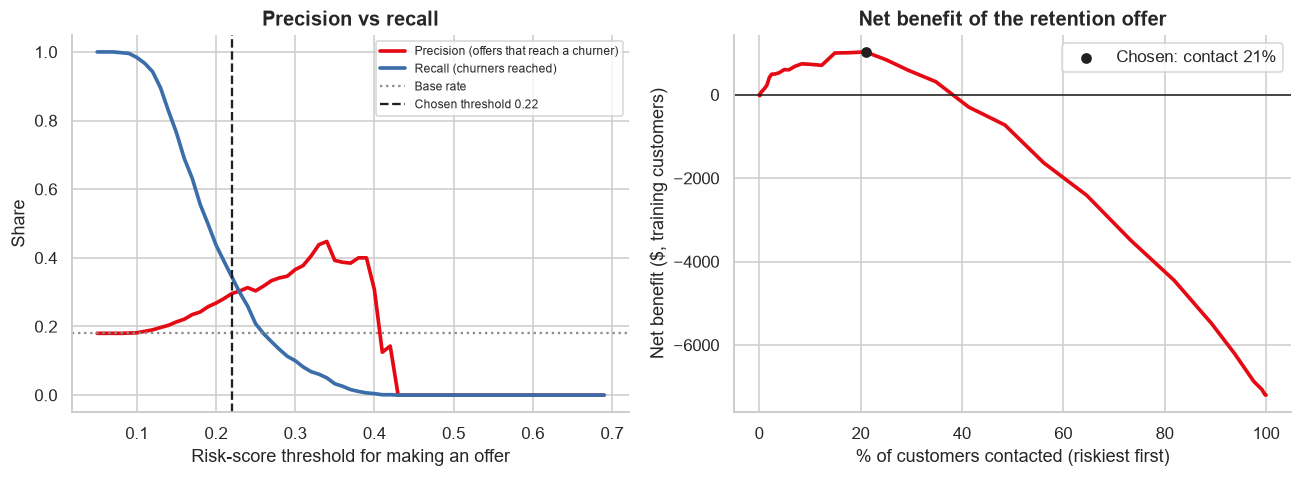

Saved chart: reports\figures\churn_02_threshold_tradeoff.png


In [16]:
# Chart 2 — Trade-offs on the training set (out-of-fold predictions)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(tt.threshold, tt.precision, color=NETFLIX_RED, lw=2.4, label="Precision (offers that reach a churner)")
ax.plot(tt.threshold, tt.recall, color=BLUE, lw=2.4, label="Recall (churners reached)")
ax.axhline(y_train.mean(), color=GREY, ls=":", label="Base rate")
ax.axvline(THRESHOLD, color=DARK, ls="--", label=f"Chosen threshold {THRESHOLD:.2f}")
ax.set_xlabel("Risk-score threshold for making an offer"); ax.set_ylabel("Share"); ax.set_title("Precision vs recall"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(tt.pct_flagged * 100, tt.net_benefit, color=NETFLIX_RED, lw=2.4)
ax.axhline(0, color=DARK, lw=1)
i = tt.threshold.sub(THRESHOLD).abs().idxmin()
ax.scatter([tt.pct_flagged[i] * 100], [tt.net_benefit[i]], color=DARK, zorder=5, label=f"Chosen: contact {tt.pct_flagged[i]:.0%}")
ax.set_xlabel("% of customers contacted (riskiest first)"); ax.set_ylabel("Net benefit ($, training customers)")
ax.set_title("Net benefit of the retention offer"); ax.legend()
finish(2, "threshold_tradeoff", fig)

## 7 · Hold-out evaluation

The test set has not been used for any choice so far. Everything below is the honest estimate of how the model would do on customers it has never seen.

In [17]:
res = classification_report_row(y_test, p_test, THRESHOLD)
res_f1 = classification_report_row(y_test, p_test, F1_THRESHOLD)
auc_ci = bootstrap_ci(y_test, p_test, roc_auc_score)
pr_ci = bootstrap_ci(y_test, p_test, average_precision_score)

summary = pd.DataFrame({
    f"Net-benefit threshold ({THRESHOLD:.2f})": res, f"F1 threshold ({F1_THRESHOLD:.2f})": res_f1}).drop(["tn", "fp", "fn", "tp"])
display(summary.round(3))
print(f"ROC-AUC {res['roc_auc']:.3f}  (95% CI {auc_ci[0]:.3f}-{auc_ci[1]:.3f})")
print(f"PR-AUC  {res['pr_auc']:.3f}  (95% CI {pr_ci[0]:.3f}-{pr_ci[1]:.3f})   no-skill = {y_test.mean():.3f}")

# every tuned model on the test set, for transparency (the final model was chosen with cross-validation, not with this table)
rows = [{"model": n, "test_roc_auc": roc_auc_score(y_test, s.best_estimator_.predict_proba(X_test)[:, 1]),
         "test_pr_auc": average_precision_score(y_test, s.best_estimator_.predict_proba(X_test)[:, 1])} for n, s in tuned.items()]
display(pd.DataFrame(rows).set_index("model").round(3))

,Net-benefit threshold (0.22),F1 threshold (0.17)
threshold,0.220,0.171
accuracy,0.724,0.571
precision,0.273,0.226
recall,0.321,0.574
f1,0.295,0.325
roc_auc,0.597,0.597
pr_auc,0.243,0.243


ROC-AUC 0.597  (95% CI 0.562-0.632)
PR-AUC  0.243  (95% CI 0.211-0.286)   no-skill = 0.180


,test_roc_auc,test_pr_auc
model,,
Logistic Regression,0.599,0.245
Random Forest,0.589,0.237
Gradient Boosting,0.595,0.234
XGBoost,0.599,0.240


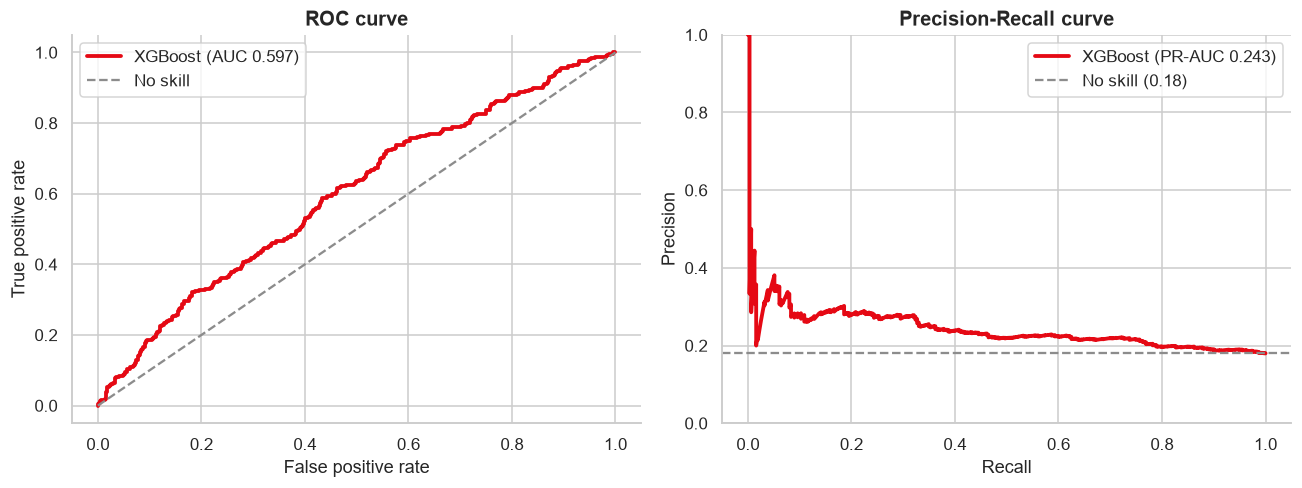

Saved chart: reports\figures\churn_03_roc_pr_curves.png


In [18]:
# Chart 3 — ROC and Precision-Recall curves (test set)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=NETFLIX_RED, lw=2.5, label=f"{final_name} (AUC {res['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", label="No skill")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve"); axes[0].legend()
pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rc, pr, color=NETFLIX_RED, lw=2.5, label=f"{final_name} (PR-AUC {res['pr_auc']:.3f})")
axes[1].axhline(y_test.mean(), color=GREY, ls="--", label=f"No skill ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curve"); axes[1].legend()
axes[1].set_ylim(0, 1)
finish(3, "roc_pr_curves", fig)

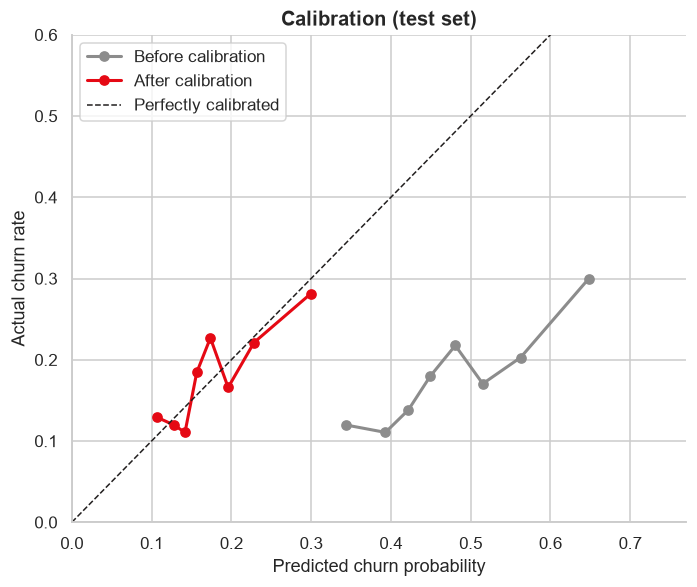

Saved chart: reports\figures\churn_04_calibration.png


In [19]:
# Chart 4 — Are the probabilities trustworthy? (calibration before and after)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for p, label, color in [(p_test_raw, "Before calibration", GREY), (p_test, "After calibration", NETFLIX_RED)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=color, lw=2, label=label)
ax.plot([0, 1], [0, 1], color=DARK, ls="--", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Predicted churn probability"); ax.set_ylabel("Actual churn rate"); ax.set_title("Calibration (test set)"); ax.legend()
ax.set_xlim(0, max(p_test_raw.max(), 0.6)); ax.set_ylim(0, 0.6)
finish(4, "calibration", fig)

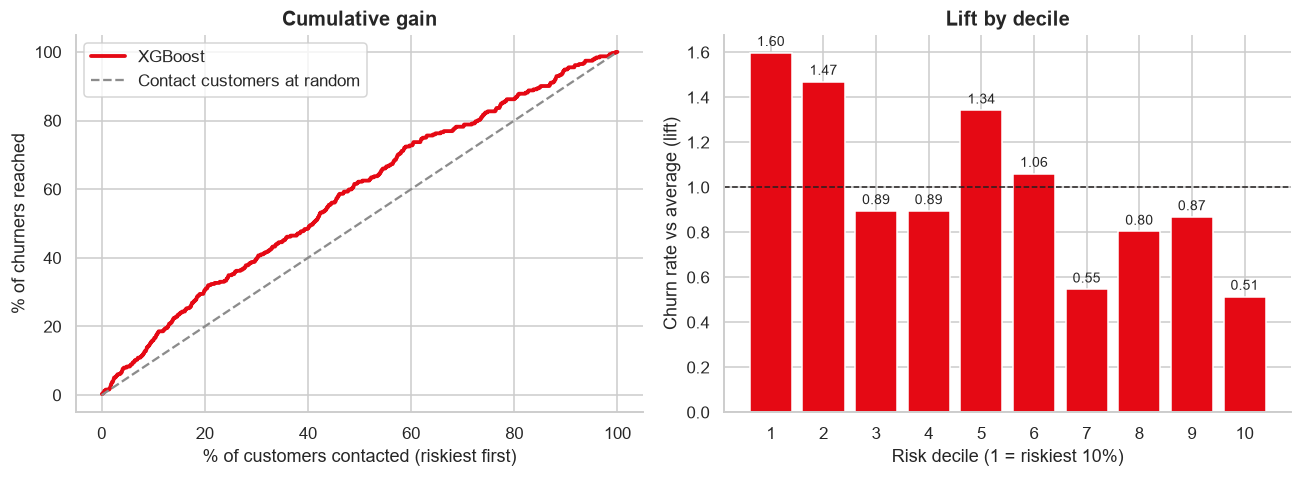

Saved chart: reports\figures\churn_05_gain_and_lift.png
Riskiest 10% churn at 28.7% (lift 1.60x); riskiest 30% capture 40% of churners.


In [20]:
# Chart 5 — Cumulative gain and lift: what do we get by contacting only the riskiest customers?
gain_x, gain_y = gain_curve(y_test, p_test)
order = np.argsort(-p_test, kind="mergesort"); ys = np.asarray(y_test)[order]
deciles = np.array_split(ys, 10)
lift = [d.mean() / y_test.mean() for d in deciles]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(gain_x * 100, gain_y * 100, color=NETFLIX_RED, lw=2.5, label=final_name)
axes[0].plot([0, 100], [0, 100], color=GREY, ls="--", label="Contact customers at random")
axes[0].set_xlabel("% of customers contacted (riskiest first)"); axes[0].set_ylabel("% of churners reached")
axes[0].set_title("Cumulative gain"); axes[0].legend()
axes[1].bar(range(1, 11), lift, color=NETFLIX_RED)
axes[1].axhline(1, color=DARK, ls="--", lw=1)
for i, v in enumerate(lift, 1): axes[1].text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=9)
axes[1].set_xlabel("Risk decile (1 = riskiest 10%)"); axes[1].set_ylabel("Churn rate vs average (lift)")
axes[1].set_xticks(range(1, 11)); axes[1].set_title("Lift by decile")
finish(5, "gain_and_lift", fig)
print(f"Riskiest 10% churn at {lift[0] * y_test.mean():.1%} (lift {lift[0]:.2f}x); riskiest 30% capture {np.interp(30, gain_x * 100, gain_y * 100):.0f}% of churners.")

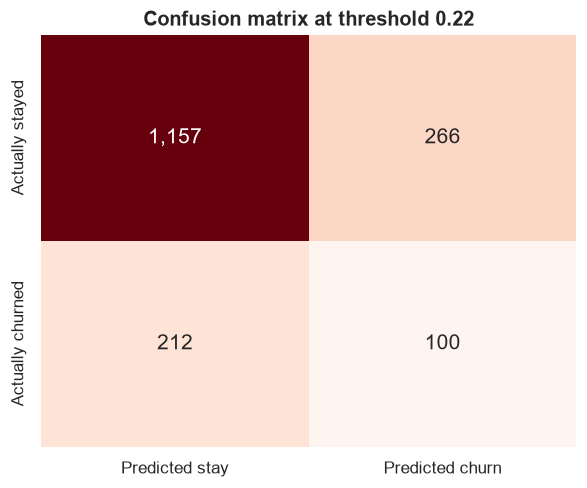

Saved chart: reports\figures\churn_06_confusion_matrix.png
Of 366 customers flagged, 100 really churned (precision 27.3%); 100 of 312 churners were reached (recall 32.1%).


In [21]:
# Chart 6 — Confusion matrix at the chosen threshold (test set)
cm = np.array([[res["tn"], res["fp"]], [res["fn"], res["tp"]]])
fig, ax = plt.subplots(figsize=(5.5, 4.6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Reds", cbar=False, ax=ax, annot_kws={"size": 14},
            xticklabels=["Predicted stay", "Predicted churn"], yticklabels=["Actually stayed", "Actually churned"])
ax.set_title(f"Confusion matrix at threshold {THRESHOLD:.2f}")
finish(6, "confusion_matrix", fig)
print(f"Of {cm[:, 1].sum():,} customers flagged, {res['tp']:,} really churned (precision {res['precision']:.1%}); "
      f"{res['tp']:,} of {cm[1].sum():,} churners were reached (recall {res['recall']:.1%}).")

## 8 · What drives the prediction?

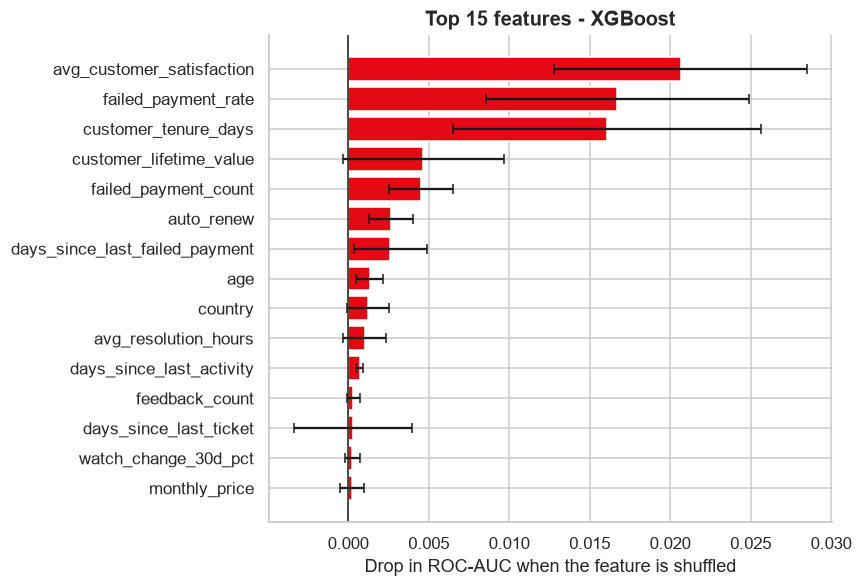

Saved chart: reports\figures\churn_07_permutation_importance.png
Top 5: avg_customer_satisfaction, failed_payment_rate, customer_tenure_days, customer_lifetime_value, failed_payment_count


In [22]:
# Chart 7 — Permutation importance: how much does ROC-AUC drop when a feature is shuffled? (test set)
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)
top = imp.sort_values("importance", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.importance, xerr=top["std"], color=NETFLIX_RED, capsize=3)
ax.axvline(0, color=DARK, lw=1)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled"); ax.set_title(f"Top 15 features - {final_name}")
finish(7, "permutation_importance", fig)
print("Top 5:", ", ".join(top.index[::-1][:5]))

## 9 · Why we do NOT use end-of-data features: the leakage experiment

This is the same model, trained the "obvious" way: measure every feature **today** (2026-06-30) for **all** 8,000 customers and predict `churned`. It looks spectacular, and it is worthless.

In [23]:
from src.database.connection import get_engine
from src.features.load_tables import load_clean_tables

tables = load_clean_tables(get_engine())
AS_OF = pd.Timestamp(meta["as_of"])
X_naive = bf.build_snapshot(tables, AS_OF, population="registered")                # includes customers who already left
y_naive = tables["churn_labels"].set_index("customer_id").churned.astype(int).reindex(X_naive.index)
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_naive, y_naive, test_size=0.25, stratify=y_naive, random_state=RANDOM_STATE)

naive_model = make_models()["Gradient Boosting"].fit(Xn_tr, yn_tr)
naive_auc = roc_auc_score(yn_te, naive_model.predict_proba(Xn_te)[:, 1])
pin = permutation_importance(naive_model, Xn_te, yn_te, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
leaky = pd.Series(pin.importances_mean, index=Xn_te.columns).sort_values(ascending=False)
print(f"Naive model (features measured after the outcome):  ROC-AUC = {naive_auc:.3f}")
print(f"Honest model (features measured before the outcome): ROC-AUC = {res['roc_auc']:.3f}")
print("\nWhat the naive model leans on:"); display(leaky.head(5).round(3).to_frame("importance"))
print("Customers with no plan on the last day of the data (plan 'Unknown', so monthly_price is missing) are exactly the ones whose subscription already ended:",
      f"{(X_naive.plan_name == 'Unknown').sum():,} customers, churn rate {y_naive[X_naive.plan_name == 'Unknown'].mean():.0%}")

Naive model (features measured after the outcome):  ROC-AUC = 0.999
Honest model (features measured before the outcome): ROC-AUC = 0.597

What the naive model leans on:


,importance
monthly_price,0.478
avg_watch_time_per_session,0.001
n_devices,0.000
avg_completion_pct,0.000
support_ticket_count,0.000


Customers with no plan on the last day of the data (plan 'Unknown', so monthly_price is missing) are exactly the ones whose subscription already ended: 1,984 customers, churn rate 100%


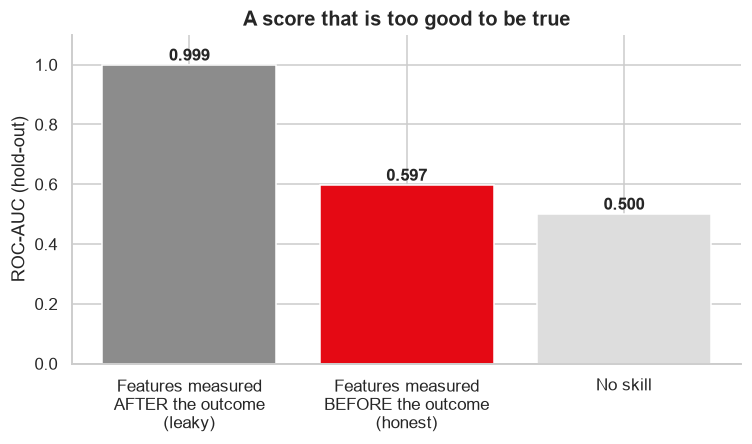

Saved chart: reports\figures\churn_08_leakage_experiment.png


In [24]:
# Chart 8 — Same algorithm, two ways of building the features
fig, ax = plt.subplots(figsize=(7, 4.2))
vals = [naive_auc, res["roc_auc"], 0.5]
labels = ["Features measured\nAFTER the outcome\n(leaky)", "Features measured\nBEFORE the outcome\n(honest)", "No skill"]
ax.bar(labels, vals, color=[GREY, NETFLIX_RED, "#DDDDDD"])
for x, v in enumerate(vals): ax.text(x, v + 0.015, f"{v:.3f}", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 1.1); ax.set_ylabel("ROC-AUC (hold-out)"); ax.set_title("A score that is too good to be true")
finish(8, "leakage_experiment", fig)

## 10 · Save the model and score today's customers

In [25]:
# Save the model, its settings and its metrics
joblib.dump(final_model, MODELS / "churn_model.joblib")
config = {"model": final_name, "target": TARGET, "train_cutoff": meta["train_cutoff"], "horizon_days": meta["horizon_days"],
          "features": bf.FEATURES, "threshold": THRESHOLD, "f1_threshold": F1_THRESHOLD, "base_rate": float(y_train.mean()),
          "assumptions": {"offer_cost": OFFER_COST, "save_rate": SAVE_RATE, "months_saved": MONTHS_SAVED,
                          "value_if_saved": float(VALUE_IF_SAVED)}}
json.dump(config, open(MODELS / "churn_config.json", "w"), indent=2)

metrics = {"model": final_name, "n_train": int(len(X_train)), "n_test": int(len(X_test)), "test_churn_rate": float(y_test.mean()),
           "cv_pr_auc": float(tuned_table.cv_pr_auc[final_name]), "cv_roc_auc": float(tuned_table.cv_roc_auc[final_name]),
           "test": {k: float(v) for k, v in res.items()}, "test_roc_auc_ci": list(auc_ci), "test_pr_auc_ci": list(pr_ci),
           "top_decile_lift": float(lift[0]), "naive_leaky_roc_auc": float(naive_auc),
           "all_models_cv": {n: {"cv_pr_auc": float(r.cv_pr_auc), "cv_roc_auc": float(r.cv_roc_auc)} for n, r in tuned_table.iterrows()}}
json.dump(metrics, open(REPORTS / "churn_model_metrics.json", "w"), indent=2)

# Score every customer who is active today (features as of the end of the data)
X_now = pd.read_csv(PROCESSED / "customer_features_current.csv", index_col="customer_id", keep_default_na=False, na_values=[""])
score = final_model.predict_proba(X_now[bf.FEATURES])[:, 1]
scores = pd.DataFrame({"churn_risk_score": score}, index=X_now.index)
scores["risk_band"] = np.select([score >= THRESHOLD, score >= y_train.mean()], ["High", "Medium"], "Low")
scores.to_csv(PROCESSED / "churn_scores_current.csv")

print("Saved models/churn_model.joblib, models/churn_config.json, reports/churn_model_metrics.json")
print("Saved data/processed/churn_scores_current.csv")
print(scores.risk_band.value_counts().to_string())

Saved models/churn_model.joblib, models/churn_config.json, reports/churn_model_metrics.json
Saved data/processed/churn_scores_current.csv
risk_band
Low       3392
High      1452
Medium    1165


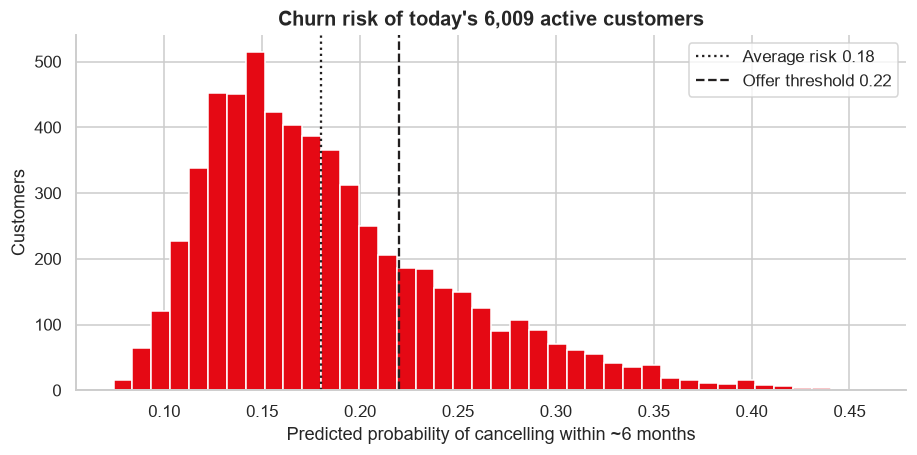

Saved chart: reports\figures\churn_09_current_risk_scores.png


,churn_risk_score,risk_band,plan_name,failed_payment_rate,support_ticket_count,days_since_last_activity
customer_id,,,,,,
CUST002294,0.460,High,Basic,0.500,2.0,8.0
CUST002259,0.439,High,Standard,0.267,2.0,24.0
CUST000725,0.433,High,Basic,0.333,3.0,205.0
CUST001968,0.433,High,Basic,0.267,1.0,2.0
CUST003751,0.430,High,Basic,0.200,2.0,19.0
CUST004422,0.426,High,Standard,0.250,2.0,16.0
CUST005917,0.424,High,Standard,0.333,2.0,31.0
CUST000630,0.423,High,Basic,0.200,1.0,18.0
CUST002414,0.420,High,Standard,0.250,2.0,28.0


In [26]:
# Chart 9 — Risk scores of today's active customers
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.hist(scores.churn_risk_score, bins=40, color=NETFLIX_RED, edgecolor="white")
ax.axvline(y_train.mean(), color=DARK, ls=":", label=f"Average risk {y_train.mean():.2f}")
ax.axvline(THRESHOLD, color=DARK, ls="--", label=f"Offer threshold {THRESHOLD:.2f}")
ax.set_xlabel("Predicted probability of cancelling within ~6 months"); ax.set_ylabel("Customers")
ax.set_title(f"Churn risk of today's {len(scores):,} active customers"); ax.legend()
finish(9, "current_risk_scores", fig)
cols = ["churn_risk_score", "risk_band", "plan_name", "failed_payment_rate", "support_ticket_count", "days_since_last_activity"]
display(scores.join(X_now).sort_values("churn_risk_score", ascending=False)[cols].head(10).round(3))

## 11 · Model selection and justification

In [27]:
gain30 = float(np.interp(30, gain_x * 100, gain_y * 100))
print(f'''FINAL MODEL: {final_name} (calibrated)

WHY THIS MODEL
- Cross-validated PR-AUC {tuned_table.cv_pr_auc[final_name]:.3f} (best of the candidates was {tuned_table.cv_pr_auc.max():.3f}); candidates within 0.005 were
  treated as equal and the simplest was preferred. In a noisy problem a simple model generalises as well as a complex one
  and is easier to explain to a retention manager.
- Hold-out ROC-AUC {res["roc_auc"]:.3f} (95% CI {auc_ci[0]:.3f}-{auc_ci[1]:.3f}) and PR-AUC {res["pr_auc"]:.3f} against a no-skill {y_test.mean():.3f}.
- It beats the baseline clearly but is not a crystal ball: the riskiest 10% of customers churn at {lift[0] * y_test.mean():.1%} versus {y_test.mean():.1%} on average
  (lift {lift[0]:.2f}x), and contacting the riskiest 30% reaches about {gain30:.0f}% of the churners.

PRECISION / RECALL TRADE-OFF (retention offers)
- At the chosen threshold ({THRESHOLD:.2f}) we flag {res["fp"] + res["tp"]:,} of {len(y_test):,} test customers: {res["precision"]:.1%} of them really churn (precision) and we
  reach {res["recall"]:.1%} of all churners (recall).
- A lower threshold reaches more churners but spends offers on many customers who would have stayed; a higher one is cheaper
  but lets most churners leave. With an offer cost of ${OFFER_COST:.0f}, a {SAVE_RATE:.0%} save rate and ${VALUE_IF_SAVED:,.0f} of revenue kept per save, an offer breaks even at
  {BREAK_EVEN_PRECISION:.0%} precision, which is why only the riskiest part of the ranking is worth contacting.
- The model is only moderately accurate, so the economics decide. The net-benefit threshold ({THRESHOLD:.2f}) favours precision and reaches {res["recall"]:.0%} of churners;
  the F1 threshold ({F1_THRESHOLD:.2f}) reaches {res_f1["recall"]:.0%} of churners but at {res_f1["precision"]:.0%} precision, right around break-even. A cheaper offer or a higher
  save rate would justify a lower threshold and more recall. Change the three assumptions in Section 6 and the threshold moves with them.

WHAT WE DELIBERATELY DID NOT DO
- Features measured at the end of the data give ROC-AUC {naive_auc:.3f} but only because they reveal customers who already left (Section 9).
''')

FINAL MODEL: XGBoost (calibrated)

WHY THIS MODEL
- Cross-validated PR-AUC 0.279 (best of the candidates was 0.279); candidates within 0.005 were
  treated as equal and the simplest was preferred. In a noisy problem a simple model generalises as well as a complex one
  and is easier to explain to a retention manager.
- Hold-out ROC-AUC 0.597 (95% CI 0.562-0.632) and PR-AUC 0.243 against a no-skill 0.180.
- It beats the baseline clearly but is not a crystal ball: the riskiest 10% of customers churn at 28.7% versus 18.0% on average
  (lift 1.60x), and contacting the riskiest 30% reaches about 40% of the churners.

PRECISION / RECALL TRADE-OFF (retention offers)
- At the chosen threshold (0.22) we flag 366 of 1,735 test customers: 27.3% of them really churn (precision) and we
  reach 32.1% of all churners (recall).
- A lower threshold reaches more churners but spends offers on many customers who would have stayed; a higher one is cheaper
  but lets most churners leave. With an offer cost 